# Luxury Fashion Market Intelligence
### Competitive pricing, product assortment and discount analysis | Farfetch France | 17 November 2023

**Objective.** Explore how product listings differ across fashion categories and brands in terms of assortment size, listed prices and discounts. This is a portfolio analysis of a **historical product-listing snapshot**, not sales or live-market data.

**Workflow.** Load the Parquet file → assess data quality → focus on four fashion categories → compare assortment, prices and discounts → export a product-level CSV for the BI dashboard.

**Tools:** Python, pandas, matplotlib; subsequent analysis used PostgreSQL and a Looker Studio dashboard.

**Data access:** The original Parquet file is **not included** in this notebook. Obtain it from the original source subject to its terms and set `DATA_PATH` below. Dataset provenance should be verified before any redistribution.

**How to run:** Install `pandas`, `pyarrow` and `matplotlib`, provide the Parquet file, then run cells from top to bottom. Google Colab users may upload the file to `/content/` or use a mounted Drive path.


In [ ]:
from pathlib import Path
import pandas as pd

# Load the Farfetch luxury fashion dataset
DATA_PATH = Path("/content/train-00000-of-00001-e9c39afe125c6e6d.parquet")  # Update for your environment
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Input Parquet file not found: {DATA_PATH}. Update DATA_PATH above.")
df = pd.read_parquet(DATA_PATH)

# Check the dataset size
print("Dataset shape:", df.shape)

# Display the first five rows
df.head()

Dataset shape: (610641, 17)


,website_name,competence_date,country_code,currency_code,brand,category1_code,category2_code,category3_code,product_code,title,itemurl,imageurl,full_price,price,full_price_eur,price_eur,flg_discount
0,Farfetch,2023-11-17,FRA,EUR,VICTORIA BECKHAM,CLOTHING,DRESSES,DAY DRESSES,19514199,cut-out knitted midi dress,http://www.farfetch.com/fr/shopping/women/vict...,https://cdn-images.farfetch-contents.com/19/51...,978.0,978.0,978.0,978.0,0
1,Farfetch,2023-11-17,FRA,EUR,DOLCE & GABBANA,CLOTHING,PANTS,WIDE-LEG PANTS,16531707,pantalon palazzo à empiècements contrastants,http://www.farfetch.com/fr/shopping/women/dolc...,https://cdn-images.farfetch-contents.com/16/53...,795.0,795.0,795.0,795.0,0
2,Farfetch,2023-11-17,FRA,EUR,DSQUARED2 KIDS,TEEN BOY CLOTHING,TEEN SHORTS,TEEN CASUAL SHORTS,17732628,logo-print cotton shorts,http://www.farfetch.com/fr/shopping/kids/dsqua...,https://cdn-images.farfetch-contents.com/17/73...,170.0,85.0,170.0,85.0,1
3,Farfetch,2023-11-17,FRA,EUR,BAR JEWELLERY,JEWELRY,EARRINGS,None,15382494,Sfera twisted earrings,http://www.farfetch.com/fr/shopping/women/bar-...,https://cdn-images.farfetch-contents.com/15/38...,476.0,476.0,476.0,476.0,0
4,Farfetch,2023-11-17,FRA,EUR,BONTONI,SHOES,BOOTS,None,19193758,suede lace-up boots,http://www.farfetch.com/fr/shopping/men/bonton...,https://cdn-images.farfetch-contents.com/19/19...,2200.0,2200.0,2200.0,2200.0,0


## 1. Initial data exploration
Review the available product categories and the number of brands before defining the fashion subset.

In [ ]:
# Check the available product categories
print("PRODUCT CATEGORIES")
print(df["category1_code"].value_counts())

# Check the number of brands
print("\nNUMBER OF BRANDS")
print(df["brand"].nunique())

# Check the dates covered
print("\nDATASET DATES")
print(df["competence_date"].value_counts())

PRODUCT CATEGORIES
category1_code
CLOTHING                 291236
SHOES                     81975
ACCESSORIES               53809
BAGS                      34461
JEWELRY                   18667
PRE-OWNED                 18296
TEEN GIRL CLOTHING        17112
TEEN BOY CLOTHING         14850
HOMEWARE                  13863
FINE JEWELRY              10060
BABY GIRL CLOTHING         7686
BABY BOY CLOTHING          7024
GIRLS CLOTHING             6613
LINGERIE & NIGHTWEAR       5799
BOYS CLOTHING              5555
ACTIVEWEAR                 3303
UNDERWEAR & SOCKS          3170
BOYS SHOES                 2388
TEEN GIRL SHOES            2291
TEEN BOY SHOES             2285
TEEN GIRL ACCESSORIES      1728
WATCHES                    1490
GIRLS SHOES                1458
TEEN BOY ACCESSORIES       1115
NURSERY                    1016
BABY BOY SHOES              838
GIRLS ACCESSORIES           578
BABY GIRL SHOES             553
BOYS ACCESSORIES            543
BABY BOY ACCESSORIES        353
BABY G

## 2. Data quality assessment
Inspect missing values and duplicate rows. These checks describe the source; they do not automatically justify dropping records.

In [ ]:
# Check missing values in each column
print("MISSING VALUES")
print(df.isnull().sum())

# Check duplicate rows
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

# Check data types
print("\nDATA TYPES")
print(df.dtypes)

MISSING VALUES
website_name            0
competence_date         0
country_code            0
currency_code           0
brand                   0
category1_code          0
category2_code          0
category3_code     230260
product_code            0
title                   0
itemurl                 0
imageurl                0
full_price              0
price                   0
full_price_eur          0
price_eur               0
flg_discount            0
dtype: int64

DUPLICATE ROWS
0

DATA TYPES
website_name        object
competence_date     object
country_code        object
currency_code       object
brand               object
category1_code      object
category2_code      object
category3_code      object
product_code         int64
title               object
itemurl             object
imageurl            object
full_price         float64
price              float64
full_price_eur     float64
price_eur          float64
flg_discount         int64
dtype: object


In [ ]:
# Check which categories have missing third-level classifications

missing_categories = (
    df[df["category3_code"].isnull()]
    ["category1_code"]
    .value_counts()
)

print("MISSING CATEGORY 3 VALUES BY MAIN CATEGORY")
print(missing_categories)

MISSING CATEGORY 3 VALUES BY MAIN CATEGORY
category1_code
SHOES                    58943
ACCESSORIES              53809
BAGS                     34456
JEWELRY                  18665
PRE-OWNED                16517
CLOTHING                 16481
FINE JEWELRY             10060
LINGERIE & NIGHTWEAR      4900
UNDERWEAR & SOCKS         2986
BOYS SHOES                2183
TEEN BOY SHOES            1838
HOMEWARE                  1350
TEEN GIRL SHOES           1207
WATCHES                    958
NURSERY                    900
BABY BOY SHOES             787
GIRLS SHOES                785
TEEN GIRL CLOTHING         596
TEEN BOY CLOTHING          561
BABY GIRL SHOES            448
ACTIVEWEAR                 267
TEEN BOY ACCESSORIES       238
TEEN GIRL ACCESSORIES      235
BOYS CLOTHING              234
GIRLS CLOTHING             213
DEMI-FINE JEWELRY          186
BOYS ACCESSORIES           165
GIRLS ACCESSORIES          137
BABY GIRL ACCESSORIES      114
BABY BOY ACCESSORIES        41
Name: count,

In [ ]:
# Check how many product codes are repeated
print("TOTAL PRODUCT LISTINGS:", len(df))

print("UNIQUE PRODUCT CODES:", df["product_code"].nunique())

print("DUPLICATED PRODUCT CODES:",
      df["product_code"].duplicated().sum())

TOTAL PRODUCT LISTINGS: 610641
UNIQUE PRODUCT CODES: 610641
DUPLICATED PRODUCT CODES: 0


### Price checks
Inspect price distributions and flag zero or negative values. Outliers are investigated rather than automatically removed.

In [ ]:
# Check price statistics
print("PRICE SUMMARY")
print(df[["full_price_eur", "price_eur"]].describe())

# Check zero or negative prices
print("\nZERO OR NEGATIVE PRICES")
print((df["price_eur"] <= 0).sum())

# Check selling prices higher than original prices
print("\nSELLING PRICE ABOVE ORIGINAL PRICE")
print((df["price_eur"] > df["full_price_eur"]).sum())

# Check discount indicators
print("\nDISCOUNT INDICATORS")
print(df["flg_discount"].value_counts())

PRICE SUMMARY
       full_price_eur     price_eur
count    6.106410e+05  6.106410e+05
mean     8.512227e+02  7.912528e+02
std      3.474104e+03  3.462254e+03
min      1.300000e+01  1.100000e+01
25%      2.040000e+02  1.790000e+02
50%      3.950000e+02  3.490000e+02
75%      7.850000e+02  6.950000e+02
max      1.201755e+06  1.201755e+06

ZERO OR NEGATIVE PRICES
0

SELLING PRICE ABOVE ORIGINAL PRICE
0

DISCOUNT INDICATORS
flg_discount
0    444138
1    166503
Name: count, dtype: int64


In [ ]:
# Display the 10 most expensive products
top_expensive = df.nlargest(10, "price_eur")

# Show relevant product information
top_expensive[
    [
        "brand",
        "category1_code",
        "category2_code",
        "title",
        "full_price_eur",
        "price_eur"
    ]
]

,brand,category1_code,category2_code,title,full_price_eur,price_eur
552574,PATEK PHILIPPE,PRE-OWNED,PRE-OWNED FINE WATCHES,pre-owned Nautilus 44mm,1201755.0,1201755.0
414052,RICHARD MILLE,PRE-OWNED,PRE-OWNED FINE WATCHES,pre-owned RM30 43mm,549483.0,549483.0
444485,AUDEMARS PIGUET,PRE-OWNED,PRE-OWNED FINE WATCHES,2021 pre-owned Royal Oak 41mm,408026.0,408026.0
315527,ROLEX,PRE-OWNED,PRE-OWNED FINE WATCHES,2019 unworn Day-Date 40mm,369609.0,369609.0
272421,ROLEX,PRE-OWNED,PRE-OWNED FINE WATCHES,2021 pre-owned GMT Master II 40mm,288442.0,288442.0
430805,PATEK PHILIPPE,PRE-OWNED,PRE-OWNED FINE WATCHES,2022 pre-owned Grand Complications 42mm,281378.0,281378.0
174072,PATEK PHILIPPE,PRE-OWNED,PRE-OWNED FINE WATCHES,2014 pre-owned Nautilus 40mm,267306.0,267306.0
351230,ROLEX,PRE-OWNED,PRE-OWNED FINE WATCHES,2013 pre-owned Daytona Cosmograph 40mm,254400.0,254400.0
189526,AUDEMARS PIGUET,PRE-OWNED,PRE-OWNED FINE WATCHES,pre-owned Royal Oak Offshore 42mm,231774.0,231774.0
31706,KWIAT,FINE JEWELRY,FINE BRACELETS,18kt white gold diamond Moonlight 15-row bracelet,213300.0,213300.0


## 3. Define the analysis scope
Keep **CLOTHING, SHOES, BAGS and ACCESSORIES**. All reported listing counts refer to this selected subset.

In [ ]:
# Select the four fashion categories for our analysis
fashion_categories = [
    "CLOTHING",
    "SHOES",
    "BAGS",
    "ACCESSORIES"
]

# Create a separate dataset
fashion_df = df[
    df["category1_code"].isin(fashion_categories)
].copy()

# Check the new dataset
print("Original dataset:", df.shape)
print("Fashion dataset:", fashion_df.shape)

# Check category distribution
print("\nFASHION CATEGORIES")
print(fashion_df["category1_code"].value_counts())

Original dataset: (610641, 17)
Fashion dataset: (461481, 17)

FASHION CATEGORIES
category1_code
CLOTHING       291236
SHOES           81975
ACCESSORIES     53809
BAGS            34461
Name: count, dtype: int64


## 4. Brand assortment and competitive pricing
Compare listing volume and price levels. Brand-level differences may partly reflect differences in product mix.

In [ ]:
# Count unique brands in our fashion dataset
print("TOTAL FASHION BRANDS")
print(fashion_df["brand"].nunique())

# Identify the 20 brands with the most product listings
print("\nTOP 20 BRANDS BY PRODUCT LISTINGS")
print(fashion_df["brand"].value_counts().head(20))

TOTAL FASHION BRANDS
2362

TOP 20 BRANDS BY PRODUCT LISTINGS
brand
DOLCE & GABBANA       7098
NIKE                  5753
PRADA                 5256
PHILIPP PLEIN         5077
DSQUARED2             4901
GUCCI                 4844
BURBERRY              3931
GIUSEPPE ZANOTTI      3923
OFF-WHITE             3903
POLO RALPH LAUREN     3902
SAINT LAURENT         3863
ALEXANDER MCQUEEN     3788
VALENTINO GARAVANI    3726
MOSCHINO              3708
BALENCIAGA            3472
BRUNELLO CUCINELLI    3376
JIL SANDER            3322
DIESEL                3212
KARL LAGERFELD        3121
ETRO                  3107
Name: count, dtype: int64


In [ ]:
# Select the 20 brands with the most listings
top_20_brands = fashion_df["brand"].value_counts().head(20).index

# Calculate pricing statistics for these brands
brand_pricing = (
    fashion_df[fashion_df["brand"].isin(top_20_brands)]
    .groupby("brand")
    .agg(
        product_count=("product_code", "count"),
        average_price=("price_eur", "mean"),
        median_price=("price_eur", "median")
    )
    .sort_values("median_price", ascending=False)
)

# Round prices to two decimal places
brand_pricing = brand_pricing.round(2)

brand_pricing

,product_count,average_price,median_price
brand,,,
PRADA,5256,1569.20,1200.0
BRUNELLO CUCINELLI,3376,1842.10,1150.0
SAINT LAURENT,3863,1418.38,995.0
GUCCI,4844,1266.19,980.0
VALENTINO GARAVANI,3726,1371.16,980.0
BALENCIAGA,3472,1231.63,895.0
JIL SANDER,3322,1005.60,790.0
DOLCE & GABBANA,7098,1200.85,750.0
ALEXANDER MCQUEEN,3788,1042.58,741.0


In [ ]:
# Compare median prices by brand and product category
category_pricing = (
    fashion_df[fashion_df["brand"].isin(top_20_brands)]
    .groupby(["brand", "category1_code"])
    .agg(
        product_count=("product_code", "count"),
        median_price=("price_eur", "median")
    )
    .reset_index()
)

# Display the results
category_pricing.head(20)

,brand,category1_code,product_count,median_price
0,ALEXANDER MCQUEEN,ACCESSORIES,693,290.0
1,ALEXANDER MCQUEEN,BAGS,489,1432.0
2,ALEXANDER MCQUEEN,CLOTHING,1811,950.0
3,ALEXANDER MCQUEEN,SHOES,795,650.0
4,BALENCIAGA,ACCESSORIES,537,350.0
5,BALENCIAGA,BAGS,706,1790.0
6,BALENCIAGA,CLOTHING,1409,1100.0
7,BALENCIAGA,SHOES,820,875.0
8,BRUNELLO CUCINELLI,ACCESSORIES,395,550.0
9,BRUNELLO CUCINELLI,BAGS,105,2551.0


### Category-controlled example: bags
Comparing brands within one category reduces (but does not eliminate) product-mix differences.

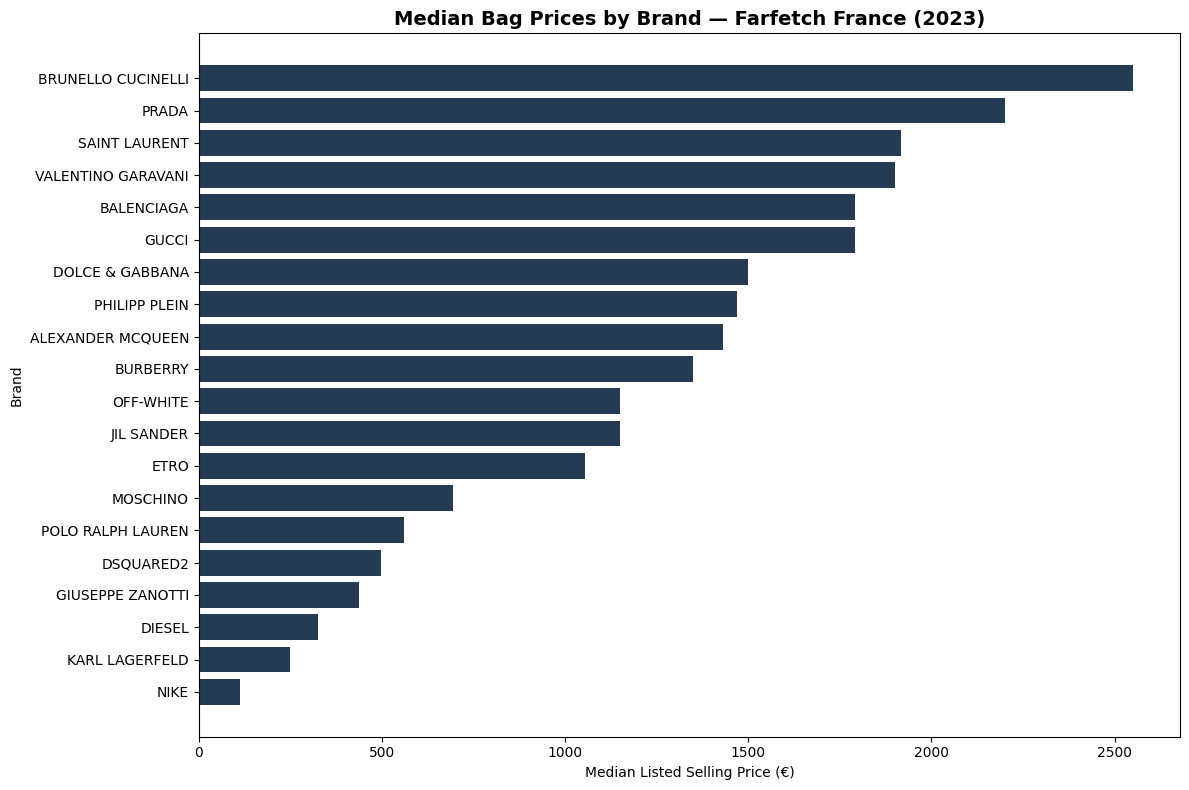

In [ ]:
import matplotlib.pyplot as plt

# Select bag listings from our category pricing table
bags_pricing = category_pricing[
    category_pricing["category1_code"] == "BAGS"
].copy()

# Sort brands by median bag price
bags_pricing = bags_pricing.sort_values(
    "median_price",
    ascending=True
)

# Create the chart
plt.figure(figsize=(12, 8))

plt.barh(
    bags_pricing["brand"],
    bags_pricing["median_price"],
    color="#243B53"
)

plt.title(
    "Median Bag Prices by Brand — Farfetch France (2023)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Median Listed Selling Price (€)")
plt.ylabel("Brand")

plt.tight_layout()
plt.show()

In [ ]:
# Select all bag listings
bags_df = fashion_df[
    fashion_df["category1_code"] == "BAGS"
].copy()

# Check the different bag types
print("BAG TYPES")
print(bags_df["category2_code"].value_counts())

BAG TYPES
category2_code
TOTE BAGS                     11011
SHOULDER BAGS                  9455
MESSENGER & CROSSBODY BAGS     5393
CLUTCH BAGS                    2036
BACKPACKS                      1593
MINI BAGS                      1517
MESSENGER BAGS                  888
BUCKET BAGS                     781
BELT BAGS                       616
LUGGAGE & HOLDALLS              510
LAPTOP BAGS & BRIEFCASES        227
BAG ACCESSORIES                 174
LUGGAGE                          71
WALLETS & PURSES                 54
BEACH BAGS                       49
LAPTOP BAGS                      38
PHONE CASES & TECHNOLOGY         15
WALLETS & BILLFOLDS              10
KEYRINGS & CHAINS                 8
TRAVEL ACCESSORIES                4
KEYCHAINS & KEYRINGS              3
BELTS                             2
MAKE UP BAGS                      2
PERFORMANCE ACCESSORIES           2
TOILETRY BAGS                     1
SKIWEAR                           1
Name: count, dtype: int64


In [ ]:
# Select tote bags from our top 20 brands
tote_df = bags_df[
    (bags_df["category2_code"] == "TOTE BAGS") &
    (bags_df["brand"].isin(top_20_brands))
].copy()

# Compare tote bag prices by brand
tote_pricing = (
    tote_df.groupby("brand")
    .agg(
        product_count=("product_code", "count"),
        median_price=("price_eur", "median"),
        average_price=("price_eur", "mean")
    )
    .sort_values("median_price", ascending=False)
    .round(2)
)

tote_pricing

,product_count,median_price,average_price
brand,,,
PRADA,392,2670.5,2665.45
BRUNELLO CUCINELLI,28,2536.0,2690.43
VALENTINO GARAVANI,182,2100.0,2113.57
SAINT LAURENT,216,1990.0,2020.91
GUCCI,179,1980.0,2183.35
BALENCIAGA,271,1790.0,1893.41
ALEXANDER MCQUEEN,78,1690.0,1700.53
JIL SANDER,190,1559.5,1553.31
DOLCE & GABBANA,161,1518.0,1841.13


## 5. Discount frequency and depth
**Discount rate** is the share of listings flagged as discounted. **Discount depth** is the percentage reduction from full price to listed price. Discount depth is evaluated among discounted listings when indicated. Neither measure represents units sold.

In [ ]:
# Analyse discount activity among our top 20 brands
discount_analysis = (
    fashion_df[fashion_df["brand"].isin(top_20_brands)]
    .groupby("brand")
    .agg(
        total_products=("product_code", "count"),
        discounted_products=("flg_discount", "sum")
    )
)

# Calculate the percentage of discounted listings
discount_analysis["discount_rate_pct"] = (
    discount_analysis["discounted_products"]
    / discount_analysis["total_products"]
    * 100
)

# Sort brands by discount rate
discount_analysis = (
    discount_analysis
    .sort_values("discount_rate_pct", ascending=False)
    .round(2)
)

discount_analysis

,total_products,discounted_products,discount_rate_pct
brand,,,
GIUSEPPE ZANOTTI,3923,3044,77.59
PHILIPP PLEIN,5077,2962,58.34
OFF-WHITE,3903,1847,47.32
DSQUARED2,4901,1931,39.40
KARL LAGERFELD,3121,1189,38.10
JIL SANDER,3322,906,27.27
POLO RALPH LAUREN,3902,949,24.32
DOLCE & GABBANA,7098,1648,23.22
MOSCHINO,3708,855,23.06


In [ ]:
# Calculate discount percentage for each product
fashion_df["discount_pct"] = (
    (fashion_df["full_price_eur"] - fashion_df["price_eur"])
    / fashion_df["full_price_eur"]
    * 100
)

# Analyse discount depth among our top 20 brands
discount_depth = (
    fashion_df[
        (fashion_df["brand"].isin(top_20_brands)) &
        (fashion_df["discount_pct"] > 0)
    ]
    .groupby("brand")
    .agg(
        discounted_products=("product_code", "count"),
        average_discount_pct=("discount_pct", "mean"),
        median_discount_pct=("discount_pct", "median")
    )
    .sort_values("median_discount_pct", ascending=False)
    .round(2)
)

discount_depth

,discounted_products,average_discount_pct,median_discount_pct
brand,,,
PHILIPP PLEIN,2962,52.80,60.00
GIUSEPPE ZANOTTI,3044,52.71,50.00
OFF-WHITE,1847,40.08,44.85
DOLCE & GABBANA,1648,38.65,40.00
DSQUARED2,1931,37.02,39.51
KARL LAGERFELD,1189,39.93,37.19
BALENCIAGA,1,34.95,34.95
ETRO,605,33.57,34.92
NIKE,60,31.56,34.41


### Validate the discount flag
Compare the supplied discount indicator with the price-based indicator; preserve the results of this quality check.

In [ ]:
# Check whether the discount flag agrees with the prices
fashion_df["calculated_discount_flag"] = (
    fashion_df["price_eur"] < fashion_df["full_price_eur"]
).astype(int)

# Count mismatches between the two indicators
mismatches = (
    fashion_df["flg_discount"]
    != fashion_df["calculated_discount_flag"]
).sum()

print("TOTAL FASHION LISTINGS:", len(fashion_df))
print("DISCOUNT FLAG MISMATCHES:", mismatches)

# Compare the two indicators
print("\nDISCOUNT FLAG COMPARISON")
print(
    pd.crosstab(
        fashion_df["flg_discount"],
        fashion_df["calculated_discount_flag"]
    )
)


TOTAL FASHION LISTINGS: 461481
DISCOUNT FLAG MISMATCHES: 0

DISCOUNT FLAG COMPARISON
calculated_discount_flag       0       1
flg_discount                            
0                         331037       0
1                              0  130444


### Brand-level discount comparison
Explore whether brands that discount more frequently also offer deeper discounts. Any association is descriptive, not causal.

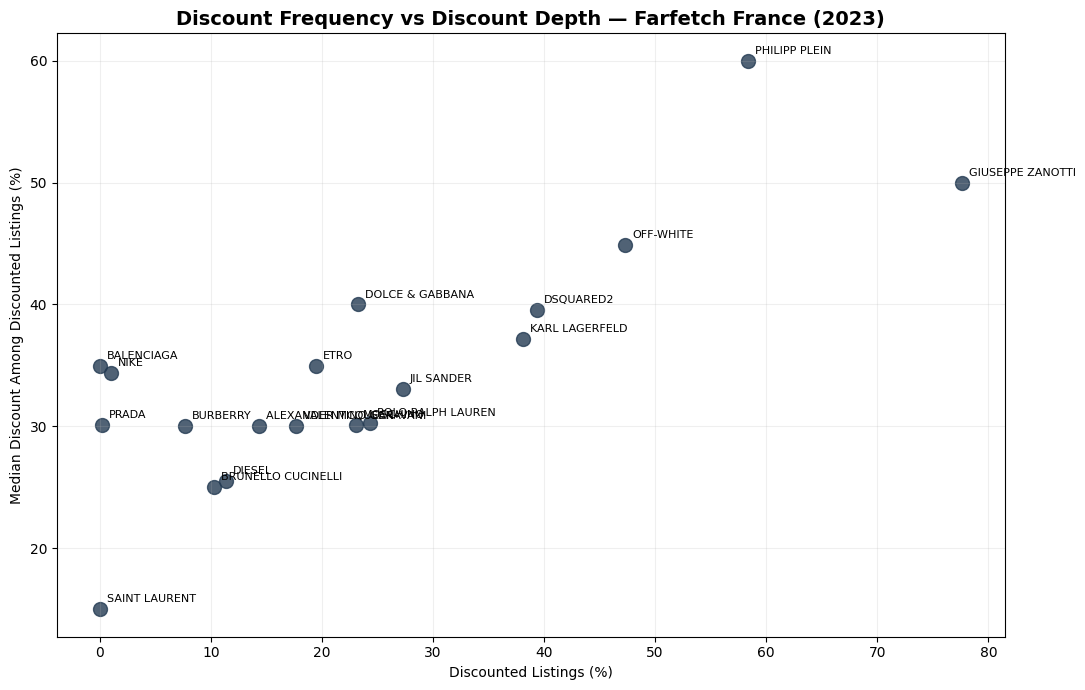

In [ ]:
import matplotlib.pyplot as plt

# Combine discount frequency and discount depth
discount_comparison = discount_analysis.join(
    discount_depth[["median_discount_pct"]],
    how="left"
)

# Exclude brands without discounted products
discount_comparison = discount_comparison.dropna(
    subset=["median_discount_pct"]
)

# Create scatter plot
plt.figure(figsize=(11, 7))

plt.scatter(
    discount_comparison["discount_rate_pct"],
    discount_comparison["median_discount_pct"],
    s=100,
    color="#243B53",
    alpha=0.8
)

# Add brand labels
for brand, row in discount_comparison.iterrows():
    plt.annotate(
        brand,
        (
            row["discount_rate_pct"],
            row["median_discount_pct"]
        ),
        fontsize=8,
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title(
    "Discount Frequency vs Discount Depth — Farfetch France (2023)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Discounted Listings (%)")
plt.ylabel("Median Discount Among Discounted Listings (%)")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [ ]:
# Keep brands with at least 30 discounted listings
reliable_brands = discount_comparison[
    discount_comparison["discounted_products"] >= 30
].copy()

# Calculate Pearson correlation
correlation = reliable_brands[
    ["discount_rate_pct", "median_discount_pct"]
].corr().iloc[0, 1]

print("Brands included:", len(reliable_brands))
print("Pearson correlation:", round(correlation, 3))

Brands included: 16
Pearson correlation: 0.838


In [ ]:
# Calculate correlation using all 16 brands
original_corr = reliable_brands[
    ["discount_rate_pct", "median_discount_pct"]
].corr().iloc[0, 1]

# Remove the two brands with the highest discount frequencies
without_top_two = reliable_brands.drop(
    ["GIUSEPPE ZANOTTI", "PHILIPP PLEIN"]
)

# Recalculate correlation
new_corr = without_top_two[
    ["discount_rate_pct", "median_discount_pct"]
].corr().iloc[0, 1]

print("Original correlation:", round(original_corr, 3))
print("Correlation without top two brands:", round(new_corr, 3))
print("Brands remaining:", len(without_top_two))

Original correlation: 0.838
Correlation without top two brands: 0.726
Brands remaining: 14


## 6. Category-level discount comparison
Compare the four fashion categories using the same discount-rate definition.

In [ ]:
# Calculate discount rates by product category
category_discounts = (
    fashion_df
    .groupby("category1_code")
    .agg(
        total_products=("product_code", "count"),
        discounted_products=("flg_discount", "sum")
    )
)

# Calculate discount percentage
category_discounts["discount_rate_pct"] = (
    category_discounts["discounted_products"]
    / category_discounts["total_products"]
    * 100
)

# Sort by discount rate
category_discounts = (
    category_discounts
    .sort_values("discount_rate_pct", ascending=False)
    .round(2)
)

category_discounts

,total_products,discounted_products,discount_rate_pct
category1_code,,,
CLOTHING,291236,96701,33.20
SHOES,81975,22806,27.82
BAGS,34461,4735,13.74
ACCESSORIES,53809,6202,11.53


## 7. Clothing subcategory comparison
Focus on T-shirts and vests to compare brands within a more consistent product group. Sample-size thresholds are applied in the code before interpreting comparisons.

In [ ]:
# Select clothing listings from our top 20 brands
clothing_df = fashion_df[
    (fashion_df["category1_code"] == "CLOTHING") &
    (fashion_df["brand"].isin(top_20_brands))
].copy()

# Calculate discount rates for clothing by brand
clothing_discounts = (
    clothing_df
    .groupby("brand")
    .agg(
        total_products=("product_code", "count"),
        discounted_products=("flg_discount", "sum")
    )
)

# Calculate discount percentage
clothing_discounts["discount_rate_pct"] = (
    clothing_discounts["discounted_products"]
    / clothing_discounts["total_products"]
    * 100
)

# Sort by highest discount rate
clothing_discounts = (
    clothing_discounts
    .sort_values("discount_rate_pct", ascending=False)
    .round(2)
)

clothing_discounts

,total_products,discounted_products,discount_rate_pct
brand,,,
GIUSEPPE ZANOTTI,163,130,79.75
PHILIPP PLEIN,3733,2323,62.23
OFF-WHITE,2412,1423,59.00
KARL LAGERFELD,1676,727,43.38
DSQUARED2,3693,1596,43.22
JIL SANDER,2126,665,31.28
VALENTINO GARAVANI,1506,461,30.61
MOSCHINO,2154,651,30.22
DOLCE & GABBANA,4465,1212,27.14


In [ ]:
# Examine clothing subcategories
clothing_types = (
    clothing_df["category2_code"]
    .value_counts()
)

print("CLOTHING SUBCATEGORIES")
print(clothing_types)

CLOTHING SUBCATEGORIES
category2_code
JACKETS                   5636
TOPS                      5566
PANTS                     5298
SWEATSHIRTS & KNITWEAR    4821
DENIM                     3144
T-SHIRTS & VESTS          3072
DRESSES                   2830
KNITS                     2820
SHIRTS                    2549
COATS                     1737
SHORTS                    1623
SKIRTS                    1334
POLO SHIRTS               1045
SWIMWEAR                   756
BEACHWEAR                  669
SUITS                      260
ROMPERS                    132
PERFORMANCE TROUSERS        55
TAILORING                   39
SWIM                        15
PERFORMANCE JACKETS         13
JUMPSUITS                    8
SCARVES                      8
SKIWEAR                      4
PERFORMANCE TOPS             1
LUGGAGE & HOLDALLS           1
Name: count, dtype: int64


In [ ]:
# Select T-shirts and vests
tshirt_df = clothing_df[
    clothing_df["category2_code"] == "T-SHIRTS & VESTS"
].copy()

# Calculate discount rates by brand
tshirt_discounts = (
    tshirt_df
    .groupby("brand")
    .agg(
        total_products=("product_code", "count"),
        discounted_products=("flg_discount", "sum"),
        median_price=("price_eur", "median")
    )
)

# Calculate discount rate
tshirt_discounts["discount_rate_pct"] = (
    tshirt_discounts["discounted_products"]
    / tshirt_discounts["total_products"]
    * 100
)

# Sort by discount rate
tshirt_discounts = (
    tshirt_discounts
    .sort_values("discount_rate_pct", ascending=False)
    .round(2)
)

tshirt_discounts

,total_products,discounted_products,median_price,discount_rate_pct
brand,,,,
GIUSEPPE ZANOTTI,32,17,146.0,53.12
PHILIPP PLEIN,646,322,420.0,49.85
DSQUARED2,398,170,228.0,42.71
OFF-WHITE,151,58,412.0,38.41
NIKE,9,3,63.0,33.33
DOLCE & GABBANA,263,87,450.0,33.08
POLO RALPH LAUREN,229,53,97.0,23.14
JIL SANDER,106,22,397.0,20.75
KARL LAGERFELD,124,23,99.0,18.55


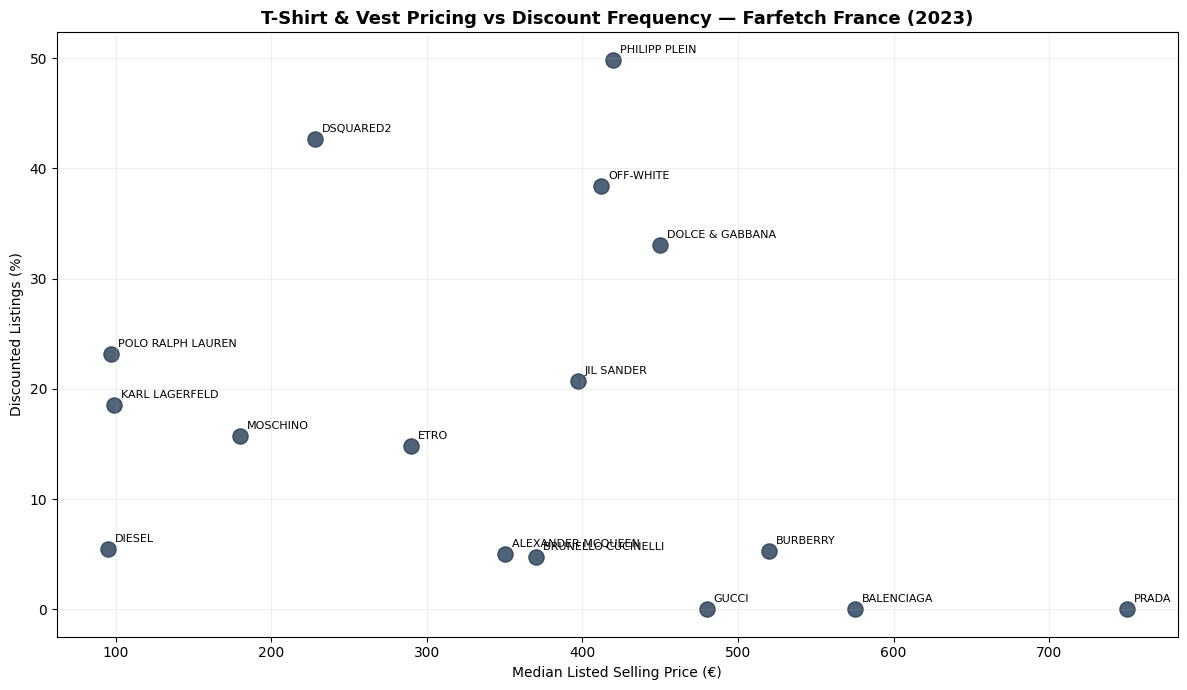

In [ ]:
# Select brands with at least 50 listings
tshirt_comparison = tshirt_discounts[
    tshirt_discounts["total_products"] >= 50
].copy()

# Create scatter plot
plt.figure(figsize=(12, 7))

plt.scatter(
    tshirt_comparison["median_price"],
    tshirt_comparison["discount_rate_pct"],
    s=120,
    color="#243B53",
    alpha=0.8
)

# Add brand labels
for brand, row in tshirt_comparison.iterrows():
    plt.annotate(
        brand,
        (row["median_price"], row["discount_rate_pct"]),
        fontsize=8,
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title(
    "T-Shirt & Vest Pricing vs Discount Frequency — Farfetch France (2023)",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Median Listed Selling Price (€)")
plt.ylabel("Discounted Listings (%)")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate Pearson correlation
price_discount_corr = tshirt_comparison[
    ["median_price", "discount_rate_pct"]
].corr().iloc[0, 1]

print("Brands included:", len(tshirt_comparison))
print(
    "Pearson correlation:",
    round(price_discount_corr, 3)
)

Brands included: 16
Pearson correlation: -0.254


In [ ]:
# Calculate original median prices by brand
original_prices = (
    tshirt_df
    .groupby("brand")
    .agg(
        median_original_price=("full_price_eur", "median")
    )
)

# Add original prices to our comparison table
tshirt_comparison = tshirt_comparison.join(
    original_prices
)

# Calculate correlation using original prices
original_price_corr = tshirt_comparison[
    ["median_original_price", "discount_rate_pct"]
].corr().iloc[0, 1]

print("Brands included:", len(tshirt_comparison))

print(
    "Correlation using selling prices:",
    round(price_discount_corr, 3)
)

print(
    "Correlation using original prices:",
    round(original_price_corr, 3)
)

Brands included: 16
Correlation using selling prices: -0.254
Correlation using original prices: -0.018


In [ ]:
# Create a consolidated T-shirt and vest comparison table
brand_comparison = (
    tshirt_df
    .groupby("brand")
    .agg(
        product_count=("product_code", "count"),
        median_original_price=("full_price_eur", "median"),
        median_selling_price=("price_eur", "median"),
        discounted_products=("flg_discount", "sum")
    )
)

# Calculate discount frequency
brand_comparison["discount_rate_pct"] = (
    brand_comparison["discounted_products"]
    / brand_comparison["product_count"]
    * 100
)

# Keep brands with at least 50 listings
brand_comparison = brand_comparison[
    brand_comparison["product_count"] >= 50
]

# Sort by median original price
brand_comparison = (
    brand_comparison
    .sort_values("median_original_price", ascending=False)
    .round(2)
)

brand_comparison

,product_count,median_original_price,median_selling_price,discounted_products,discount_rate_pct
brand,,,,,
PRADA,63,750.0,750.0,0,0.00
PHILIPP PLEIN,646,660.0,420.0,322,49.85
BALENCIAGA,121,575.0,575.0,0,0.00
BURBERRY,94,520.0,520.0,5,5.32
DOLCE & GABBANA,263,495.0,450.0,87,33.08
GUCCI,69,480.0,480.0,0,0.00
OFF-WHITE,151,475.0,412.0,58,38.41
JIL SANDER,106,410.0,397.0,22,20.75
BRUNELLO CUCINELLI,126,370.0,370.0,6,4.76


## 8. Export supplementary comparison table
Save the clothing-subcategory comparison as a separate CSV for further review.

In [ ]:
# Save our comparison table as a CSV file
brand_comparison.to_csv(
    "luxury_tshirt_brand_comparison.csv",
    index=True
)

print("Comparison table saved successfully!")

Comparison table saved successfully!


## 9. Prepare the dashboard dataset
Select the original product attributes and the derived discount percentage. The dashboard uses product listings, not aggregated sales records.

In [ ]:
# Select useful columns for our dashboard
dashboard_df = fashion_df[
    [
        "competence_date",
        "brand",
        "category1_code",
        "category2_code",
        "category3_code",
        "product_code",
        "title",
        "full_price_eur",
        "price_eur",
        "flg_discount",
        "discount_pct"
    ]
].copy()

# Check the dataset
print("Dataset shape:", dashboard_df.shape)

print("\nMissing values:")
print(dashboard_df.isnull().sum())

dashboard_df.head()

Dataset shape: (461481, 11)

Missing values:
competence_date         0
brand                   0
category1_code          0
category2_code          0
category3_code     163689
product_code            0
title                   0
full_price_eur          0
price_eur               0
flg_discount            0
discount_pct            0
dtype: int64


,competence_date,brand,category1_code,category2_code,category3_code,product_code,title,full_price_eur,price_eur,flg_discount,discount_pct
0,2023-11-17,VICTORIA BECKHAM,CLOTHING,DRESSES,DAY DRESSES,19514199,cut-out knitted midi dress,978.0,978.0,0,0.0
1,2023-11-17,DOLCE & GABBANA,CLOTHING,PANTS,WIDE-LEG PANTS,16531707,pantalon palazzo à empiècements contrastants,795.0,795.0,0,0.0
4,2023-11-17,BONTONI,SHOES,BOOTS,None,19193758,suede lace-up boots,2200.0,2200.0,0,0.0
5,2023-11-17,THOM BROWNE,CLOTHING,SHIRTS,None,19422067,whale elbow-patch detail shirt,890.0,890.0,0,0.0
6,2023-11-17,PRADA,BAGS,SHOULDER BAGS,None,19789461,triangle-logo shoulder bag,1900.0,1900.0,0,0.0


In [ ]:
# Create a clean category label for the BI dashboard
dashboard_df["category3_clean"] = (
    dashboard_df["category3_code"]
    .fillna("Not specified")
)

# Check the result
print("Missing values in category3_clean:")
print(dashboard_df["category3_clean"].isnull().sum())

print("\nMost common third-level categories:")
print(dashboard_df["category3_clean"].value_counts().head(10))

Missing values in category3_clean:
0

Most common third-level categories:
category3_clean
Not specified               163689
KNITTED SWEATERS             22554
LOW-TOPS                     17704
DAY DRESSES                  16901
T-SHIRTS                     16098
T-SHIRTS & JERSEY SHIRTS     12549
HOODIES                      11087
BLAZERS                       9918
COCKTAIL & PARTY DRESSES      7940
SHIRTS                        7921
Name: count, dtype: int64


## 10. Export the cleaned dataset
Export the selected columns to `luxury_fashion_cleaned.csv`. This file was used as the source for the interactive BI dashboard. Check data-source terms before publishing the CSV.

In [ ]:
# Export the cleaned product-level dataset
dashboard_df.to_csv(
    "luxury_fashion_cleaned.csv",
    index=False
)

# Confirm the export
print("Cleaned dataset exported successfully!")
print("Rows exported:", len(dashboard_df))
print("Columns exported:", len(dashboard_df.columns))

Cleaned dataset exported successfully!
Rows exported: 461481
Columns exported: 12


In [ ]:
# Optional: download the CSV directly when running in Google Colab.
try:
    from google.colab import files
except ImportError:
    print("Not running in Google Colab; the CSV is saved in the current working directory.")
else:
    files.download("luxury_fashion_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Interpretation and limitations

- This dataset is a **single snapshot from 17 November 2023** of listings associated with Farfetch France. It cannot establish price trends over time or describe today's market.
- Listing counts measure **assortment representation**, not demand, transactions, inventory availability or revenue.
- Listed prices and discounts do not show what consumers actually paid.
- Brand and category comparisons are descriptive; differences may reflect product assortment and positioning.
- Some third-level categories are missing in the source; the export retains the original field and adds `category3_clean` for easier dashboard use.

**Dashboard companion:** *Luxury Fashion Market Intelligence | Farfetch France*. The dashboard contains category and brand filters, three KPI cards and category/brand comparisons.

**Reproducibility note:** Outputs embedded in this notebook reflect the author's earlier execution. To reproduce them, obtain the same input Parquet snapshot and run all code cells in order.
